In [10]:
import pandas as pd
from pm4py.objects.log.util import dataframe_utils
from pm4py.objects.conversion.log import converter as log_converter

# === Executive filter: keep only realistic turnarounds (<= 4 hours) ===
MAX_TAT_MIN = 240

df = pd.read_csv("turnaround_eventlog_opensky.csv", parse_dates=["time:timestamp"])

# Filter at CASE level first, then keep only events for valid cases
case_tat = df.groupby("case:concept:name")["turnaround_minutes"].first()
valid_cases = case_tat[(case_tat > 0) & (case_tat <= MAX_TAT_MIN)].index
df = df[df["case:concept:name"].isin(valid_cases)].copy()
# === end filter ===

df = dataframe_utils.convert_timestamp_columns_in_df(df)
log = log_converter.apply(df)


In [12]:
from pm4py.algo.discovery.inductive import algorithm as inductive_miner
from pm4py.objects.conversion.process_tree import converter as pt_converter

tree = inductive_miner.apply(log)                 # returns ProcessTree
net, im, fm = pt_converter.apply(tree)            # convert to Petri net


In [13]:
from pm4py.algo.conformance.tokenreplay import algorithm as token_replay

replay = token_replay.apply(log, net, im, fm)
fitness = sum(r["trace_fitness"] for r in replay) / len(replay)
fitness


1.0

In [7]:
from pm4py.algo.discovery.dfg import algorithm as dfg_discovery
from pm4py.algo.discovery.dfg import variants as dfg_variants


In [14]:
df = df.sort_values(["case:concept:name", "time:timestamp"])

df["next_activity"] = df.groupby("case:concept:name")["concept:name"].shift(-1)
df["next_time"]     = df.groupby("case:concept:name")["time:timestamp"].shift(-1)

df["delta_seconds"] = (df["next_time"] - df["time:timestamp"]).dt.total_seconds()
edges = df.dropna(subset=["next_activity","delta_seconds"])

performance_dfg = (
    edges.groupby(["concept:name","next_activity"])["delta_seconds"]
    .mean()
    .sort_values(ascending=False)
)

performance_dfg


concept:name  next_activity
ON_BLOCK      OFF_BLOCK        6178.660152
ARRIVAL       ON_BLOCK          120.000000
OFF_BLOCK     DEPARTURE         120.000000
Name: delta_seconds, dtype: float64

In [15]:
for (a,b), sec in performance_dfg.items():
    print(f"{a} -> {b}: {sec/60:.2f} minutes")


ON_BLOCK -> OFF_BLOCK: 102.98 minutes
ARRIVAL -> ON_BLOCK: 2.00 minutes
OFF_BLOCK -> DEPARTURE: 2.00 minutes


In [16]:
case_mean = df.groupby("case:concept:name")["turnaround_minutes"].first().mean()
edge_mean = performance_dfg.loc[("ON_BLOCK","OFF_BLOCK")] / 60

print("Mean turnaround_minutes:", case_mean)
print("Mean ON_BLOCK->OFF_BLOCK:", edge_mean)


Mean turnaround_minutes: 106.97766920721777
Mean ON_BLOCK->OFF_BLOCK: 102.97766920721777


In [17]:
cases = df.groupby("case:concept:name")["turnaround_minutes"].first()
print("Cases:", cases.shape[0])
print(">= 120 min:", (cases >= 120).mean())


Cases: 30702
>= 120 min: 0.23985408116735066


In [19]:
# Proposed Method: Build Case-level Feature Table (filtered to <= 4 hours)

MAX_TAT_MIN = 240  # keep consistent with the event-log filter

cases_all = (
    df.groupby("case:concept:name")
      .agg({
          "turnaround_minutes": "first",
          "turnaround_airport": "first",
          "icao24": "first",
          "time:timestamp": "min"
      })
      .rename(columns={"time:timestamp":"arrival_time"})
      .reset_index()
)

cases_all["hour_of_day"] = cases_all["arrival_time"].dt.hour
cases_all["day_of_week"] = cases_all["arrival_time"].dt.dayofweek

util = cases_all.groupby("icao24").size().reset_index(name="flights_per_aircraft")
cases_all = cases_all.merge(util, on="icao24", how="left")

# Filtered dataset used for visuals / reporting
cases = cases_all[
    (cases_all["turnaround_minutes"] > 0) &
    (cases_all["turnaround_minutes"] <= MAX_TAT_MIN)
].copy()

print("Cases (all):", len(cases_all))
print("Cases (filtered <= 4h):", len(cases))


In [20]:
DELAY_THRESHOLD = 120
cases["delayed"] = (cases["turnaround_minutes"] > DELAY_THRESHOLD).astype(int)


### Executive add-on: Data coverage, quality, and delay cost impact

The tables and charts below are designed to communicate:
- **We are actively measuring** turnaround performance (with a realistic filter ≤ 4 hours).
- **What additional airport data would improve accuracy** (AODB / ground-handling milestones).
- **Why process improvement matters financially**, via scenario-based cost and savings estimates.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MAX_TAT_MIN = 240
DELAY_THRESHOLD_MIN = DELAY_THRESHOLD  # re-use your threshold

# --- Data coverage & quality summary ---
n_total = cases_all.shape[0]
n_kept = cases.shape[0]
kept_pct = 100 * n_kept / n_total

missing_ts_pct = df["time:timestamp"].isna().mean() * 100

events_per_case_all = df.groupby("case:concept:name").size()

# events per case for filtered cases only
df_f = df[df["case:concept:name"].isin(cases["case:concept:name"])].copy()
events_per_case_f = df_f.groupby("case:concept:name").size()

quality = pd.DataFrame({
    "Metric": [
        "Total turnarounds (cases)",
        "Turnarounds used (<= 4h)",
        "Share kept after filter",
        "Missing timestamps (events)",
        "Median events / turnaround (ALL)",
        "Median events / turnaround (FILTERED)",
        "10th pct events / turnaround (FILTERED)",
        "90th pct events / turnaround (FILTERED)",
    ],
    "Value": [
        f"{n_total:,}",
        f"{n_kept:,}",
        f"{kept_pct:.1f}%",
        f"{missing_ts_pct:.2f}%",
        f"{events_per_case_all.median():.0f}",
        f"{events_per_case_f.median():.0f}",
        f"{events_per_case_f.quantile(0.10):.0f}",
        f"{events_per_case_f.quantile(0.90):.0f}",
    ]
})

display(quality)

# --- Coverage by airport (top 10) ---
if "turnaround_airport" in cases.columns:
    airport_cov = (
        cases.groupby("turnaround_airport")["case:concept:name"]
        .count()
        .sort_values(ascending=False)
        .head(10)
        .reset_index(name="cases_count")
    )
    display(airport_cov)

    plt.figure(figsize=(10,4))
    plt.barh(airport_cov["turnaround_airport"], airport_cov["cases_count"])
    plt.xlabel("Number of filtered turnarounds (<= 4h)")
    plt.title("Top Airports by Data Coverage (Filtered cases)")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

# --- Scenario-based cost of delay (actionability for executives) ---
# delay minutes above threshold
cases["delay_minutes"] = (cases["turnaround_minutes"] - DELAY_THRESHOLD_MIN).clip(lower=0)

total_delay_minutes = cases["delay_minutes"].sum()
delayed_cases = (cases["delay_minutes"] > 0).sum()

summary_delay = pd.DataFrame({
    "Metric": ["Delayed cases (turnaround > threshold)", "Total delay minutes above threshold"],
    "Value": [f"{delayed_cases:,}", f"{total_delay_minutes:,.0f}"]
})
display(summary_delay)

# Cost scenarios (EUR per delay-minute) -- replace with airport/airline finance values when available
scenarios = {
    "Conservative (EUR 10/min)": 10,
    "Mid (EUR 30/min)": 30,
    "High (EUR 60/min)": 60
}

cost_df = pd.DataFrame(
    [(name, total_delay_minutes * eur_per_min) for name, eur_per_min in scenarios.items()],
    columns=["Scenario", "Estimated cost (EUR)"]
)
display(cost_df)

plt.figure(figsize=(10,4))
plt.bar(cost_df["Scenario"], cost_df["Estimated cost (EUR)"])
plt.ylabel("Estimated cost (EUR)")
plt.title(f"Estimated Cost of Turnaround Delays (> {DELAY_THRESHOLD_MIN} min), scenarios (<= 4h)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

# Potential savings if we reduce delay minutes
reduction_targets = [0.10, 0.20, 0.30]  # 10%, 20%, 30%
savings_rows = []
for scen_name, eur_per_min in scenarios.items():
    for r in reduction_targets:
        savings_rows.append([scen_name, f"{int(r*100)}%", total_delay_minutes * eur_per_min * r])

savings_df = pd.DataFrame(savings_rows, columns=["Scenario", "Delay reduction target", "Estimated savings (EUR)"])
display(savings_df)

# --- What extra data we need next (collaboration ask) ---
needs = pd.DataFrame({
    "Data needed": [
        "Gate in / Gate out timestamps (AODB)",
        "Ground handling milestones (fuel, cleaning, catering, bags)",
        "Stand/gate assignment & changes",
        "Resource logs (teams, vehicles, SLA timestamps)",
        "Delay reason codes (IATA/AHM)",
        "Weather / ATC constraints flags"
    ],
    "Why it matters": [
        "Accurate turnaround boundaries and variability",
        "Identify bottlenecks by subprocess (root cause)",
        "Measure impact of gate conflicts on turnaround",
        "Quantify staffing/equipment constraints and utilization",
        "Separate controllable vs. uncontrollable delays",
        "Explain peaks and build better prediction"
    ]
})
display(needs)


In [21]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

features = ["turnaround_minutes","hour_of_day","day_of_week","flights_per_aircraft"]
X = cases[features]
y = cases["delayed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

clf = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42)
clf.fit(X_train, y_train)

y_pred  = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:,1]

print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7002
           1       1.00      1.00      1.00      2209

    accuracy                           1.00      9211
   macro avg       1.00      1.00      1.00      9211
weighted avg       1.00      1.00      1.00      9211

ROC-AUC: 1.0


In [22]:
import pandas as pd

imp = pd.Series(clf.feature_importances_, index=features).sort_values(ascending=False)
imp


turnaround_minutes      0.978614
hour_of_day             0.015048
flights_per_aircraft    0.006338
day_of_week             0.000000
dtype: float64

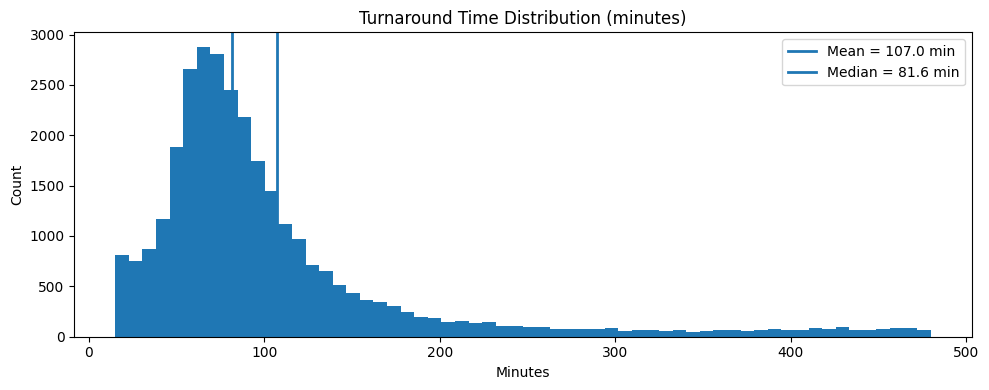

In [23]:
import matplotlib.pyplot as plt
import numpy as np

MAX_TAT_MIN = 240

tat = cases["turnaround_minutes"].dropna().values
mean_tat = np.mean(tat)
median_tat = np.median(tat)

plt.figure(figsize=(10,4))
plt.hist(tat, bins=40)
plt.axvline(mean_tat, linewidth=2, label=f"Mean = {mean_tat:.1f} min")
plt.axvline(median_tat, linewidth=2, label=f"Median = {median_tat:.1f} min")
plt.axvline(DELAY_THRESHOLD, linestyle="--", linewidth=2, label=f"Delay threshold = {DELAY_THRESHOLD} min")
plt.axvline(MAX_TAT_MIN, linestyle="--", linewidth=2, label=f"Max included = {MAX_TAT_MIN} min (4h)")
plt.xlim(0, MAX_TAT_MIN)
plt.title("Turnaround Time Distribution (Filtered: <= 4 hours)")
plt.xlabel("Minutes")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()


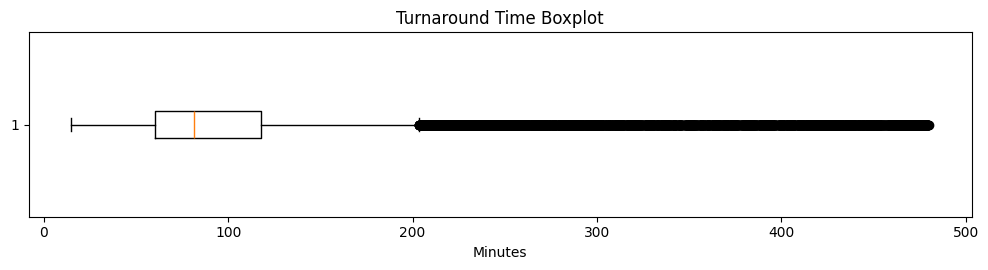

In [ ]:
# Boxplot of Turnaround Times for Outliers (Filtered <= 4 hours)
import matplotlib.pyplot as plt

MAX_TAT_MIN = 240

plt.figure(figsize=(10,2.8))
plt.boxplot(cases["turnaround_minutes"].dropna().values, vert=False, showfliers=True)
plt.xlim(0, MAX_TAT_MIN)
plt.title("Turnaround Time Boxplot (Filtered: <= 4 hours)")
plt.xlabel("Minutes")
plt.tight_layout()
plt.show()


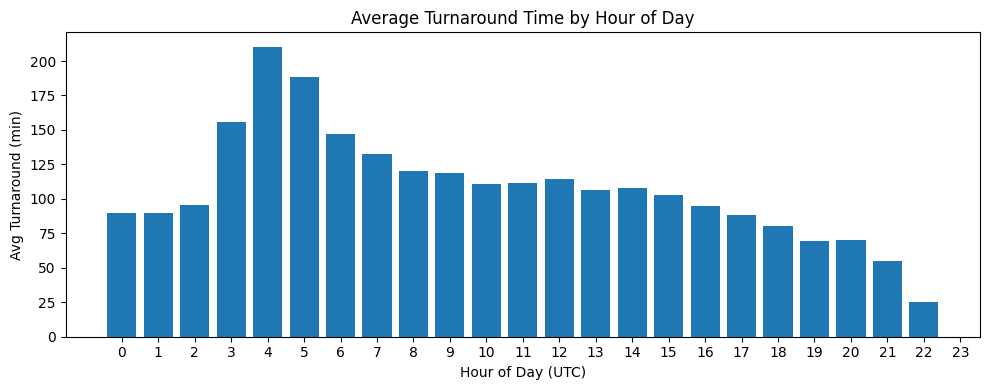

In [ ]:
# Average Turnaround Time by Hour of Day (Filtered <= 4 hours)
g = cases.groupby("hour_of_day")["turnaround_minutes"].mean()

plt.figure(figsize=(10,4))
plt.bar(g.index, g.values)
plt.title("Average Turnaround Time by Hour of Day (Filtered: <= 4 hours)")
plt.xlabel("Hour of Day (UTC)")
plt.ylabel("Avg Turnaround (min)")
plt.xticks(range(0,24))
plt.tight_layout()
plt.show()


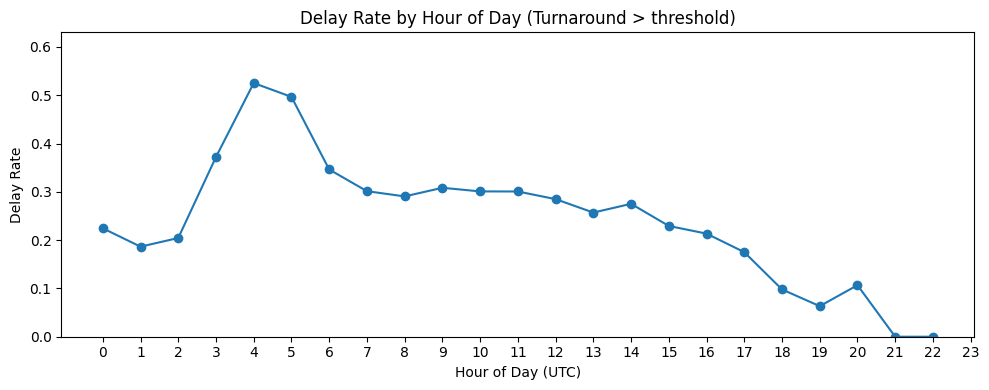

In [27]:
# Delay rate by hour of day (Filtered <= 4 hours)
rate = cases.groupby("hour_of_day")["delayed"].mean()

plt.figure(figsize=(10,4))
plt.plot(rate.index, rate.values, marker="o")
plt.title(f"Delay Rate by Hour of Day (Turnaround > {DELAY_THRESHOLD} min, filtered <= 4 hours)")
plt.xlabel("Hour of Day (UTC)")
plt.ylabel("Delay Rate")
plt.xticks(range(0,24))
plt.ylim(0, min(1.0, rate.max()*1.2))
plt.tight_layout()
plt.show()


## EU261 / UK261 compensation (for executive discussion)

**Important:** The €250/€400/€600 rule is **not IATA**; it comes from **EU Regulation (EC) 261/2004** (and the UK equivalent “UK261”).  
Compensation applies when passengers reach the **final destination** **3+ hours late** (subject to eligibility and “extraordinary circumstances” exceptions).

In this notebook we only have **turnaround** times. Turnaround is a *major driver* of departure punctuality and knock‑on delay, but to compute EU261 exposure precisely we need:
- scheduled vs actual OFF‑BLOCK / TAKE‑OFF / LANDING / ON‑BLOCK times (AODB/A‑CDM),
- passenger count (pax) per flight,
- route distance band (<=1500 km / 1500–3500 km / >3500 km),
- disruption / delay cause codes to identify “extraordinary circumstances”.

Below we provide a **scenario-based** exposure chart to translate “risky turnarounds” into **potential compensation exposure**. Replace assumptions with real airport data once shared.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# --- Define "risky" cases (proxy) ---
# NOTE: EU261 depends on ARRIVAL delay, but we use turnaround > threshold as a risk indicator.
DELAY_THRESHOLD_MIN = 120
cases["delay_minutes_over_threshold"] = (cases["turnaround_minutes"] - DELAY_THRESHOLD_MIN).clip(lower=0)
cases["risky_turnaround"] = (cases["delay_minutes_over_threshold"] > 0).astype(int)

n_risky = int(cases["risky_turnaround"].sum())
print("Filtered cases:", len(cases))
print("Risky turnarounds (> threshold):", n_risky)

# --- EU261 scenario assumptions (EDIT THESE) ---
# Compensation amounts per passenger (EU261 Article 7) by distance band:
comp_amounts = {"short": 250, "medium": 400, "long": 600}

# Mix of distance bands in your airport network (must sum to 1.0)
distance_mix = {"short": 0.6, "medium": 0.3, "long": 0.1}
expected_comp_per_pax = sum(distance_mix[k] * comp_amounts[k] for k in distance_mix)

# Share of risky turnarounds that end up as EU261-eligible 3h+ ARRIVAL delays (after excluding extraordinary circumstances)
eligible_share = np.array([0.05, 0.10, 0.20])  # 5%, 10%, 20% (EDIT)

# Average passengers per flight (EDIT; replace with real pax counts)
pax_scenarios = [120, 160, 200]

# Plot exposure per 1,000 risky turnarounds (more interpretable for executives)
plt.figure(figsize=(10,5))
for pax in pax_scenarios:
    exposure_per_1000 = 1000 * eligible_share * pax * expected_comp_per_pax
    plt.plot(eligible_share, exposure_per_1000, marker="o", label=f"{pax} pax/flight")

plt.xlabel("Assumed share of risky turnarounds that become EU261-eligible (3h+ arrival delay)")
plt.ylabel("Estimated compensation exposure (EUR) per 1,000 risky turnarounds")
plt.title("EU261 Compensation Exposure (Scenario-based; adjust assumptions)")
plt.legend()
plt.tight_layout()
plt.show()

# Export the chart for emailing
export_dir = "export_visuals"
os.makedirs(export_dir, exist_ok=True)
out_path = os.path.join(export_dir, "05_eu261_exposure_per_1000_risky.png")
plt.figure(figsize=(10,5))
for pax in pax_scenarios:
    exposure_per_1000 = 1000 * eligible_share * pax * expected_comp_per_pax
    plt.plot(eligible_share, exposure_per_1000, marker="o", label=f"{pax} pax/flight")
plt.xlabel("Assumed share of risky turnarounds that become EU261-eligible (3h+ arrival delay)")
plt.ylabel("Estimated compensation exposure (EUR) per 1,000 risky turnarounds")
plt.title("EU261 Compensation Exposure (Scenario-based; adjust assumptions)")
plt.legend()
plt.tight_layout()
plt.savefig(out_path, dpi=300)
plt.close()
print("Saved:", out_path)
